# Underwater YOLO11 — Held-out test detection examples (Colab)

Compare the seed-0 baseline (B0), CBAM before Detect (A1) and DW-HDC-SPPF (C2) on selected test images. Run all cells on a **CPU runtime** and authorise the Google Drive mount when prompted. The notebook displays the annotated images and saves a one-page PDF. In Colab, the default output is `/content/held_out_detection_examples.pdf`, available from the Files panel.

## 0) Configuration

Choose selected test filenames and one confidence threshold for all three models. The default of 0.25 follows Ultralytics `predict` mode and keeps lower-confidence boxes out of the figure. The test notebooks saved predictions using `conf=0.001` for evaluation. Adjusting the figure threshold affects only this display. [Ultralytics prediction settings](https://docs.ultralytics.com/modes/predict/#inference-arguments)

In [173]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/UnderWaterYOLO11/")
DATASET_ROOT = Path("/content/UOD_Dataset")
DATA_YAML = DATASET_ROOT / "data_split.yaml"
COCO_ANN_FILE = BASE_DIR / "instances_test2017.json"
OUTPUT_DIR = Path("/content")

# Seed-0 test runs, in figure column order.
TEST_RUN_NAME = "test-m"
MODEL_RUNS = {
    "B0": "YOLO11-baseline",
    "A1": "CBAM-detect",
    "C2": "sppf-dw-hdc-sppf",
}

SCENES = [
    ## Small objects ##
    ("Small-object scene #1", "009471.jpg"),
    ("Small-object scene #2", "004763.jpg"),
    # ("Small-object scene3", "006370.jpg"),
    # ("Small-object scene4", "010087.jpg"),
    # ("Small-object scene5", "011621.jpg"),
    # ("Small-object scene6", "004931.jpg"),
    # ("Small-object scene7", "004093.jpg"),
    ## Net and rope ##
    ("Net and rope", "net4_mp4-0091.jpg"),
    ("Net in a crowded scene", "003119.jpg"),
    # ("Net", "net.jpg"),
    ## Clear success ##
    ("Turtle and diver", "011105.jpg"),
    ("Clear success2", "010295.jpg"),
    # ("Clear success3", "003868.jpg"),
    # ("Clear success4", "012315.jpg"),
]
DISPLAY_CONFIDENCE = 0.25

## 1) Mount Google Drive

In [174]:
# Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2) Extract the dataset from Google Drive

Copy `UOD_Dataset.tar` to the Colab runtime and extract it under `/content/UOD_Dataset`. The extraction cell reuses the dataset when `data_split.yaml` is already present.

In [175]:
import tarfile
import tempfile
from tqdm.auto import tqdm

DATASET_ARCHIVE = BASE_DIR / "UOD_Dataset.tar"

if not DATASET_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Dataset archive not found:\n{DATASET_ARCHIVE}"
    )

# Extract only when the dataset is not already available.
if not DATA_YAML.is_file():
    with tempfile.TemporaryDirectory(prefix="uod_dataset_") as temp_dir:
        copied_archive = Path(temp_dir) / DATASET_ARCHIVE.name
        archive_size = DATASET_ARCHIVE.stat().st_size

        print(f"Transferring dataset from: {DATASET_ARCHIVE}")

        # Copy the archive from Google Drive to temporary local storage.
        with (
            DATASET_ARCHIVE.open("rb") as source,
            copied_archive.open("wb") as destination,
            tqdm(
                total=archive_size,
                desc="Copying dataset",
                unit="B",
                unit_scale=True,
                unit_divisor=1024,
                dynamic_ncols=True,
            ) as progress,
        ):
            while chunk := source.read(8 * 1024 * 1024):
                destination.write(chunk)
                progress.update(len(chunk))

        # Extract from the temporary local copy.
        with tarfile.open(copied_archive, "r:*") as archive:
            members = archive.getmembers()
            archive.extractall(
                path=DATASET_ROOT.parent,
                members=tqdm(
                    members,
                    total=len(members),
                    desc="Extracting dataset",
                    unit="file",
                    dynamic_ncols=True,
                ),
                filter="data",
            )

if not DATA_YAML.is_file():
    raise FileNotFoundError(
        f"Dataset configuration file not found after extraction: {DATA_YAML}"
    )

print("Dataset extracted to:", DATASET_ROOT)
print("Dataset configuration:", DATA_YAML)

Dataset extracted to: /content/UOD_Dataset
Dataset configuration: /content/UOD_Dataset/data_split.yaml


## 3) Load the test images and ground-truth annotations

Read each selected image and its YOLO label file from the extracted dataset. Use the shared `instances_test2017.json` to match filenames and class names to the COCO identifiers used in the prediction files.

In [176]:
import json
from collections import defaultdict

import yaml
from PIL import Image

with DATA_YAML.open(encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

test_manifest = DATASET_ROOT / data_config["test"]
dataset_dir = test_manifest.parent
test_images = {
    Path(ref).name: dataset_dir / ref
    for ref in test_manifest.read_text(encoding="utf-8").splitlines()
}

with COCO_ANN_FILE.open(encoding="utf-8") as f:
    coco_annotations = json.load(f)

filename_by_id = {image["id"]: Path(image["file_name"]).name for image in coco_annotations["images"]}
category_id_by_name = {c["name"]: c["id"] for c in coco_annotations["categories"]}
category_names = {cid: name.replace("_", " ") for name, cid in category_id_by_name.items()}

columns = ("Ground truth", *MODEL_RUNS)
boxes = {column: defaultdict(list) for column in columns}
images = {}
for _, name in SCENES:
    with Image.open(test_images[name]) as image:
        width, height = image.size
        images[name] = image.convert("RGB")

    label_path = dataset_dir / "labels" / f"{Path(name).stem}.txt"
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        class_id, x, y, w, h = line.split()
        x, y, w, h = map(float, (x, y, w, h))
        class_name = data_config["names"][int(class_id)]
        # Convert the YOLO centre and size to a COCO box in image pixels.
        boxes["Ground truth"][name].append({
            "category_id": category_id_by_name[class_name],
            "bbox": [(x - w / 2) * width, (y - h / 2) * height, w * width, h * height],
        })

## 4) Load the aligned test predictions

Read each model's saved boxes. Keep predictions for the selected images at or above the display confidence threshold.

In [177]:
for model, folder in MODEL_RUNS.items():
    aligned_pred_json = BASE_DIR / folder / TEST_RUN_NAME / "predictions_coco_ids.json"
    with aligned_pred_json.open(encoding="utf-8") as f:
        predictions = json.load(f)

    for prediction in predictions:
        name = filename_by_id[prediction["image_id"]]
        if name in images and prediction["score"] >= DISPLAY_CONFIDENCE:
            boxes[model][name].append(prediction)

## 5) Display the detection examples and save the PDF

Each row shows the same test image across four columns. If an image has an annotated object smaller than 1,024 square pixels, the dashed rectangle marks the region enlarged in each inset.

In [178]:
from io import BytesIO

import matplotlib as mpl
import matplotlib.patheffects as effects
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from IPython.display import Image as InlineImage, Markdown, display


def small_object_crop(name):
    small = [r for r in boxes["Ground truth"][name] if r["bbox"][2] * r["bbox"][3] <= 32**2]
    if not small:
        return None
    x, y, w, h = min(small, key=lambda r: r["bbox"][2] * r["bbox"][3])["bbox"]
    width, height = images[name].size
    crop_w = min(width, max(84, round(3.4 * w), round(5.0 * h)))
    crop_h = min(height, max(52, round(crop_w * 0.65), round(2.7 * h)))
    left = max(0, min(width - crop_w, round(x + w / 2 - crop_w / 2)))
    top = max(0, min(height - crop_h, round(y + h / 2 - crop_h / 2)))
    return left, top, left + crop_w, top + crop_h


def overlay(ax, records, colour, bounds, skip_labels_in=None, inset=False):
    left, top, right, bottom = bounds
    for record in records:
        x, y, w, h = record["bbox"]
        if x >= right or y >= bottom or x + w <= left or y + h <= top:
            continue
        line = Rectangle((x, y), w, h, fill=False, edgecolor=colour, linewidth=0.78)
        line.set_path_effects([effects.withStroke(linewidth=1.35, foreground="#152025")])
        # line = Rectangle((x, y), w, h, fill=False, edgecolor=colour, linewidth=0.45)
        # line.set_path_effects([effects.withStroke(linewidth=0.8, foreground="#152025")])
        ax.add_patch(line)
        if skip_labels_in is not None:
            x0, y0, x1, y1 = skip_labels_in
            if x0 <= x + w / 2 <= x1 and y0 <= y + h / 2 <= y1:
                continue
        # Keep labels inside the image even when a box touches its upper edge.
        above = y - top > (bottom - top) * (0.22 if inset else 0.12)
        ax.annotate(
            category_names[record["category_id"]], (max(x, left), max(y, top)),
            xytext=(1, 1 if above else -1), textcoords="offset points",
            va="bottom" if above else "top", ha="left", fontsize=5.6 if inset else 6.2,
            # va="bottom" if above else "top", ha="left", fontsize=4.6 if inset else 2.0,
            color="white", bbox=dict(facecolor="#152025", edgecolor="none", pad=0.55, alpha=0.92),
            clip_on=True,
        )


def draw_panel(ax, name, column, crop):
    img = images[name]
    width, height = img.size
    extent = (0, width, height, 0)
    ax.imshow(img, extent=extent, interpolation="lanczos")
    ax.set(xlim=(0, width), ylim=(height, 0))
    ax.set_axis_off()
    colour = "#78F5EF" if column == "Ground truth" else "#FFD85D"
    overlay(ax, boxes[column][name], colour, (0, 0, width, height), skip_labels_in=crop)
    if crop is None:
        return
    left, top, right, bottom = crop
    region = Rectangle((left, top), right-left, bottom-top, fill=False,
                       edgecolor="white", linewidth=0.65, linestyle="--")
    region.set_path_effects([effects.withStroke(linewidth=1.35, foreground="#152025")])
    ax.add_patch(region)
    zoom = ax.inset_axes([0.02, 0.57, 0.37, 0.41])
    zoom.imshow(img.crop(crop), extent=(left, right, bottom, top), interpolation="nearest")
    zoom.set(xlim=(left, right), ylim=(bottom, top), xticks=[], yticks=[])
    for spine in zoom.spines.values():
        spine.set(color="white", linewidth=0.75)
    overlay(zoom, boxes[column][name], colour, crop, inset=True)

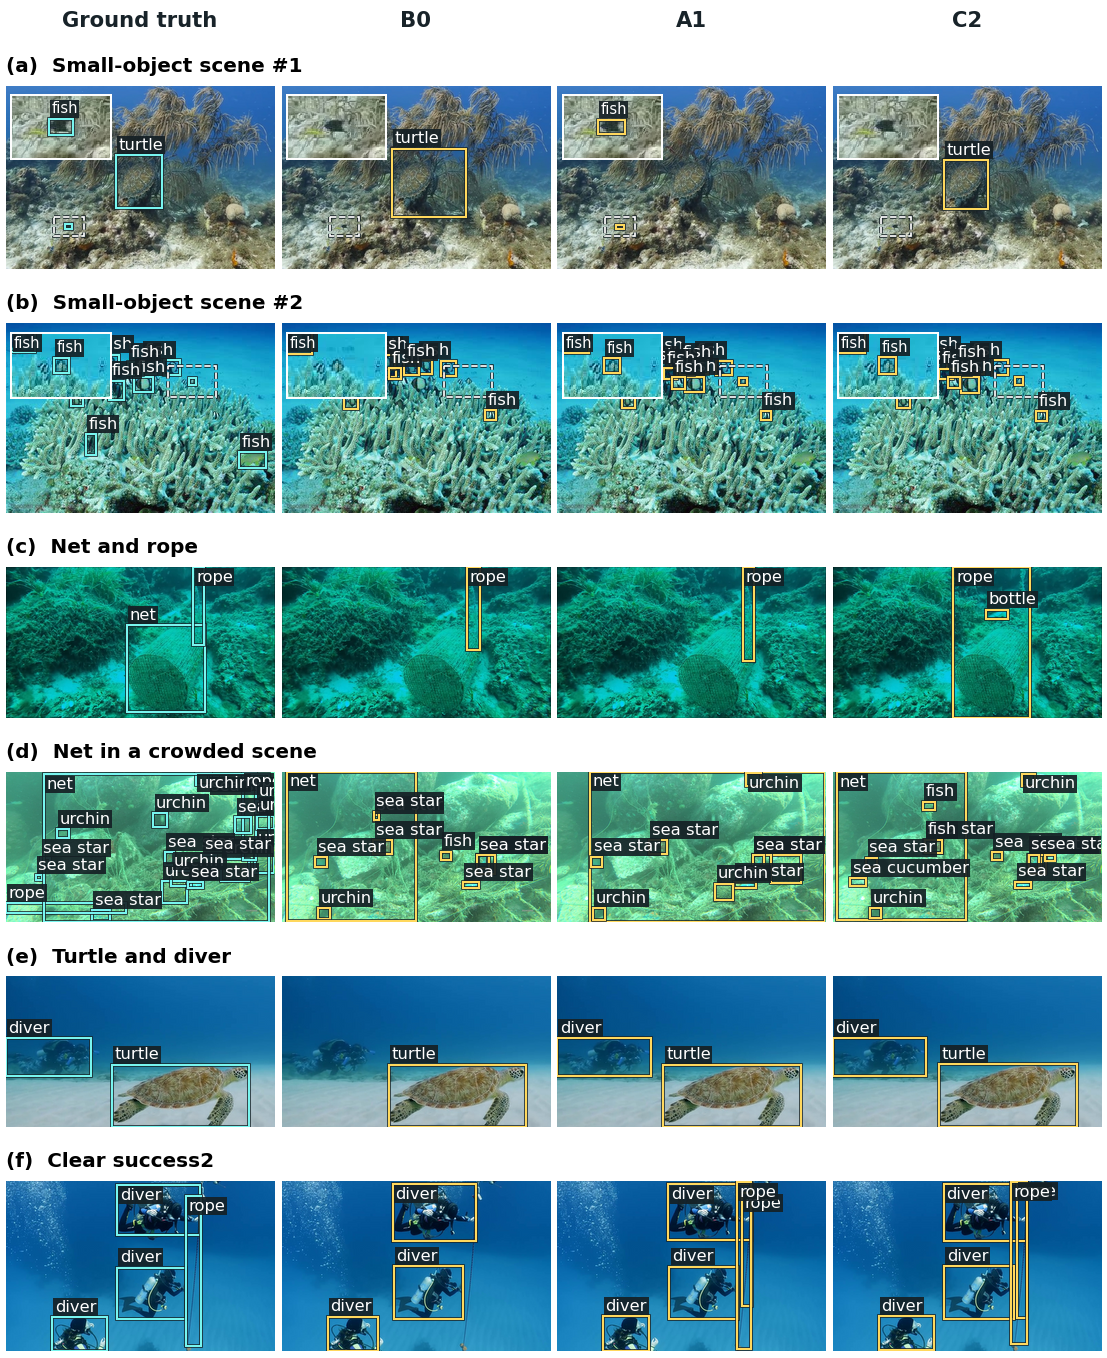

Exported /content/held_out_detection_examples.pdf (148 × 181.6 mm).


In [179]:
# Size the figure to the dissertation text block. Row heights follow the actual image shapes.
page_width_mm = 148
margin_mm, gap_mm = 0.8, 1.0
panel_width = (page_width_mm - 2 * margin_mm - 3 * gap_mm) / 4
row_heights = [panel_width * images[n].height / images[n].width for _, n in SCENES]
header_mm, row_title_mm, row_gap_mm = 6.3, 5.2, 2.0
rows = len(SCENES)
figure_height = header_mm + sum(row_heights) + rows * row_title_mm + (rows - 1) * row_gap_mm + 1.0

fig = Figure(figsize=(page_width_mm / 25.4, figure_height / 25.4), facecolor="white")
FigureCanvasAgg(fig)
for col, column in enumerate(columns):
    centre = margin_mm + col * (panel_width + gap_mm) + panel_width / 2
    fig.text(centre / page_width_mm, 1 - 2.8 / figure_height, column, ha="center",
             va="center", fontsize=8, fontweight="bold", color="#182329")

crops = {name: small_object_crop(name) for _, name in SCENES}
top = header_mm
for row, ((title, name), panel_height) in enumerate(zip(SCENES, row_heights)):
    fig.text(margin_mm / page_width_mm, 1 - (top + row_title_mm / 2) / figure_height,
             f"({chr(97 + row)})  {title}", va="center", fontsize=7.6, fontweight="bold")
    top += row_title_mm
    for col, column in enumerate(columns):
        left = margin_mm + col * (panel_width + gap_mm)
        ax = fig.add_axes([left / page_width_mm, 1 - (top + panel_height) / figure_height,
                           panel_width / page_width_mm, panel_height / figure_height])
        draw_panel(ax, name, column, crops[name])
    top += panel_height + row_gap_mm

figure_file = OUTPUT_DIR / "held_out_detection_examples.pdf"
with mpl.rc_context({"pdf.fonttype": 42}):
    fig.savefig(figure_file, format="pdf", dpi=450)
with BytesIO() as preview:
    fig.savefig(preview, format="png", dpi=190)
    # fig.savefig(preview, format="png", dpi=380)
    display(InlineImage(data=preview.getvalue(), width=900))
    # display(InlineImage(data=preview.getvalue(), width=1800))
print(f"Exported {figure_file} ({page_width_mm:g} × {figure_height:.1f} mm).")

## 6) Display the classes and confidence scores

In [180]:
def displayed_labels(column, name):
    entries = []
    for box in boxes[column][name]:
        label = category_names[box["category_id"]]
        if column != "Ground truth":
            label += f" ({box['score']:.2f})"
        entries.append(label)
    return ", ".join(entries) or "None"


table = ["| Held-out image | " + " | ".join(columns) + " |", "|" + "---|" * 5]
for _, name in SCENES:
    values = [displayed_labels(column, name) for column in columns]
    table.append(f"| {name} | " + " | ".join(values) + " |")
display(Markdown("\n".join(table)))

inset_rows = [
    f"({chr(97 + i)})"
    for i, (_, name) in enumerate(SCENES)
    if crops[name] is not None
]

caption = (
    f"Ground truth and seed-0 detections from B0, A1 and C2 on {len(SCENES)} "
    f"held-out test images. Predictions with confidence scores of "
    f"{DISPLAY_CONFIDENCE:g} or higher are shown."
)
if inset_rows:
    caption += f" Insets in {' and '.join(inset_rows)} enlarge the dashed region in each column."

display(Markdown("**Suggested caption.** " + caption))

| Held-out image | Ground truth | B0 | A1 | C2 |
|---|---|---|---|---|
| 009471.jpg | turtle, fish | turtle (0.30) | fish (0.56) | turtle (0.71) |
| 004763.jpg | fish, fish, fish, fish, fish, fish, fish, fish, fish, fish, fish | fish (0.86), fish (0.84), fish (0.78), fish (0.73), fish (0.53), fish (0.43), fish (0.38), fish (0.29), fish (0.26) | fish (0.87), fish (0.87), fish (0.86), fish (0.85), fish (0.84), fish (0.82), fish (0.80), fish (0.75), fish (0.74), fish (0.72), fish (0.60), fish (0.60) | fish (0.87), fish (0.86), fish (0.85), fish (0.85), fish (0.85), fish (0.84), fish (0.83), fish (0.83), fish (0.78), fish (0.60), fish (0.51), fish (0.34) |
| net4_mp4-0091.jpg | net, rope | rope (0.57) | rope (0.32) | bottle (0.65), rope (0.43) |
| 003119.jpg | urchin, urchin, urchin, urchin, sea star, sea star, sea star, sea star, sea star, urchin, urchin, sea star, rope, sea star, sea star, urchin, urchin, rope, urchin, net | sea star (0.78), sea star (0.74), sea star (0.71), urchin (0.70), sea star (0.55), net (0.49), sea star (0.48), sea star (0.38), sea star (0.37), sea star (0.28), fish (0.27) | net (0.92), urchin (0.87), sea star (0.81), sea star (0.78), sea star (0.73), sea star (0.62), urchin (0.54), urchin (0.40), sea star (0.38), urchin (0.34) | sea star (0.82), sea star (0.81), sea star (0.80), sea star (0.71), sea star (0.71), sea star (0.62), sea star (0.57), fish (0.55), urchin (0.50), fish (0.45), sea cucumber (0.42), net (0.42), urchin (0.34), sea star (0.26) |
| 011105.jpg | diver, turtle | turtle (0.95) | turtle (0.95), diver (0.84) | turtle (0.95), diver (0.87) |
| 010295.jpg | diver, diver, diver, rope | diver (0.92), diver (0.92), diver (0.90) | diver (0.92), diver (0.91), diver (0.86), rope (0.46), rope (0.27) | diver (0.94), diver (0.92), diver (0.91), rope (0.31), rope (0.29) |

**Suggested caption.** Ground truth and seed-0 detections from B0, A1 and C2 on 6 held-out test images. Predictions with confidence scores of 0.25 or higher are shown. Insets in (a) and (b) enlarge the dashed region in each column.